Formação Cientista de Dados - Fernando Amaral e Jones Granatyr
Limpeza e tratamento de Dados

In [3]:
import pandas as pd
import seaborn as sb
import statistics  as sts

In [4]:
# Importar dados
dataset = pd.read_csv(r"..\dados\Churn.csv", sep=";")
# Visualizar
dataset.head()

,X0,X1,X2,X3,X4,X4.1,X6,X7,X8,X9,X10,X11
0,1,619,RS,Feminino,42,2,0,1,1,1,10134888.0,1
1,2,608,SC,Feminino,41,1,8380786,1,0,1,11254258.0,0
2,3,502,RS,Feminino,42,8,1596608,3,1,0,11393157.0,1
3,4,699,RS,Feminino,39,1,0,2,0,0,9382663.0,0
4,5,850,SC,Feminino,43,2,12551082,1,1,1,790841.0,0


In [5]:
# Tamanho
dataset.shape

(999, 12)

In [6]:
# Primeiro problema é dar nomes as colunas
dataset.columns = ["Id", "Score", "Estado", "Genero", "Idade", "Patrimonio", "Saldo" ,"Produtos", "TemCartCredito",
                    "Ativo", "Salario", "Saiu"]

In [7]:
# Visualizar
dataset.head()

,Id,Score,Estado,Genero,Idade,Patrimonio,Saldo,Produtos,TemCartCredito,Ativo,Salario,Saiu
0,1,619,RS,Feminino,42,2,0,1,1,1,10134888.0,1
1,2,608,SC,Feminino,41,1,8380786,1,0,1,11254258.0,0
2,3,502,RS,Feminino,42,8,1596608,3,1,0,11393157.0,1
3,4,699,RS,Feminino,39,1,0,2,0,0,9382663.0,0
4,5,850,SC,Feminino,43,2,12551082,1,1,1,790841.0,0


In [8]:
# Explorar dados categóricos
# Estado
agrupado = dataset.groupby(['Estado']).size()
agrupado

Estado
PR    257
RP      1
RS    478
SC    258
SP      4
TD      1
dtype: int64

<Axes: xlabel='Estado'>

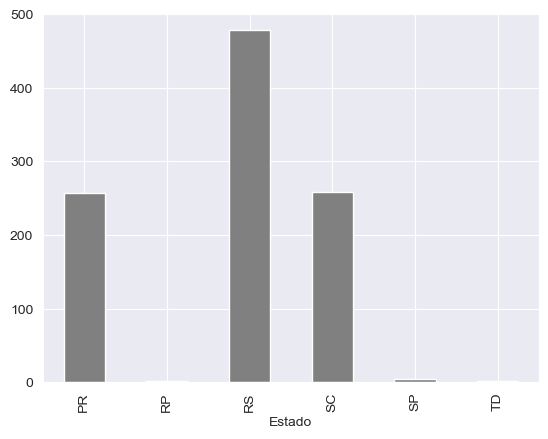

In [9]:
agrupado.plot.bar(color = 'grey')

In [10]:
# Gênero
agrupado = dataset.groupby(['Genero']).size()
agrupado

Genero
F              2
Fem            1
Feminino     461
M              6
Masculino    521
dtype: int64

<Axes: xlabel='Genero'>

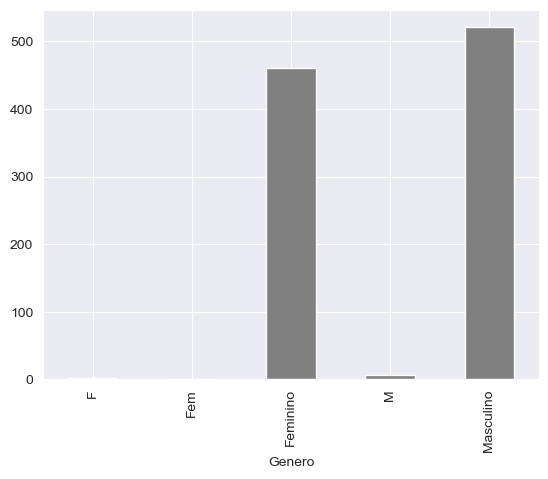

In [11]:
agrupado.plot.bar(color = 'gray')

In [12]:
# Explorar colunas numéricas
# Score
dataset['Score'].describe()

count    999.000000
mean     648.621622
std       98.264219
min      376.000000
25%      580.000000
50%      653.000000
75%      721.000000
max      850.000000
Name: Score, dtype: float64

In [13]:
# Idade
dataset['Idade'].describe()

count    999.000000
mean      38.902903
std       11.401912
min      -20.000000
25%       32.000000
50%       37.000000
75%       44.000000
max      140.000000
Name: Idade, dtype: float64

In [14]:
# Saldo
dataset['Saldo'].describe()

count    9.990000e+02
mean     7.164928e+06
std      6.311840e+06
min      0.000000e+00
25%      0.000000e+00
50%      8.958835e+06
75%      1.258684e+07
max      2.117743e+07
Name: Saldo, dtype: float64

In [15]:
# Salário anual
dataset['Salario'].describe()

count    9.920000e+02
mean     3.528762e+07
std      5.305800e+08
min      9.677000e+03
25%      3.029011e+06
50%      8.703250e+06
75%      1.405213e+07
max      1.193469e+10
Name: Salario, dtype: float64

In [16]:
# Contamos valores NAN
# Gênero e salário
dataset.isnull().sum()

Id                0
Score             0
Estado            0
Genero            8
Idade             0
Patrimonio        0
Saldo             0
Produtos          0
TemCartCredito    0
Ativo             0
Salario           7
Saiu              0
dtype: int64

In [17]:
# Salários
# Remover nas e substituir pela mediana
dataset['Salario'].describe()

count    9.920000e+02
mean     3.528762e+07
std      5.305800e+08
min      9.677000e+03
25%      3.029011e+06
50%      8.703250e+06
75%      1.405213e+07
max      1.193469e+10
Name: Salario, dtype: float64

In [18]:
mediana = sts.median(dataset['Salario'])
mediana

70518.0

In [19]:
# Substituir NAN por mediana
dataset['Salario'].fillna(mediana, inplace=True)

In [20]:
# Verificamos se NAN não existem mais
dataset['Salario'].isnull().sum()

0

In [21]:
# Genero, falta de padronização e NAs
agrupado = dataset.groupby(['Genero']).size()
agrupado

Genero
F              2
Fem            1
Feminino     461
M              6
Masculino    521
dtype: int64

In [22]:
# Total de Nas
dataset['Genero'].isnull().sum()

8

In [23]:
# Preenche NAs com Masculino (moda)
dataset['Genero'].fillna('Masculino', inplace=True)

In [24]:
# Verificamos novamente NANs
dataset['Genero'].isnull().sum()

0

In [25]:
# Moda de gênero
moda = sts.mode(dataset['Genero'])
moda

'Masculino'

In [26]:
# Padroniza de acordo com o domínio
dataset.loc[dataset['Genero'].isnull(), 'Genero'] = moda
dataset.loc[dataset['Genero'] == 'M', 'Genero'] = 'Masculino'
dataset.loc[dataset['Genero'].isin(['Fem', 'F']), 'Genero'] = 'Feminino'

In [27]:
# Visualiza o resultado
agrupado = dataset.groupby(['Genero']).size()
agrupado

Genero
Feminino     464
Masculino    535
dtype: int64

In [28]:
# Idades fora do domínio
dataset['Idade'].describe()

count    999.000000
mean      38.902903
std       11.401912
min      -20.000000
25%       32.000000
50%       37.000000
75%       44.000000
max      140.000000
Name: Idade, dtype: float64

In [29]:
# Visualizar
dataset.loc[(dataset['Idade'] < 0 ) | (dataset['Idade'] >  120)]

,Id,Score,Estado,Genero,Idade,Patrimonio,Saldo,Produtos,TemCartCredito,Ativo,Salario,Saiu
867,869,636,RS,Feminino,-10,1,17083346,1,1,0,11051028.0,1
984,986,773,RS,Masculino,-20,1,12453278,2,0,1,1172357.0,0
990,992,655,RS,Masculino,140,5,93147,2,1,0,6621413.0,0


In [30]:
# Calcular a mediana
mediana = sts.median(dataset['Idade'])
mediana

37

In [31]:
# Substituir
dataset.loc[(dataset['Idade'] <  0) | (dataset['Idade'] > 120), 'Idade'] = mediana

In [32]:
# Verificamos se ainda existem idades fora do domínio
dataset.loc[(dataset['Idade'] <  0 ) | (dataset['Idade'] > 120)]

,Id,Score,Estado,Genero,Idade,Patrimonio,Saldo,Produtos,TemCartCredito,Ativo,Salario,Saiu


In [33]:
# Dados duplicados, buscamos pelo ID
dataset[dataset.duplicated(['Id'],keep=False)]

,Id,Score,Estado,Genero,Idade,Patrimonio,Saldo,Produtos,TemCartCredito,Ativo,Salario,Saiu
80,81,665,RS,Feminino,34,1,9664554,2,0,0,17141366.0,0
81,81,665,RS,Feminino,34,1,9664554,2,0,0,17141366.0,0


In [34]:
# Excluímos pelo ID
dataset.drop_duplicates(subset='Id', keep='first', inplace=True)
# Buscamos duplicados
dataset[dataset.duplicated(['Id'], keep=False)]

,Id,Score,Estado,Genero,Idade,Patrimonio,Saldo,Produtos,TemCartCredito,Ativo,Salario,Saiu


In [35]:
# Estado foram do domínio
agrupado = dataset.groupby(['Estado']).size()
agrupado

Estado
PR    257
RP      1
RS    477
SC    258
SP      4
TD      1
dtype: int64

In [36]:
moda = sts.mode(dataset['Estado'])
moda

'RS'

In [37]:
# Atribuímos RS (moda)
dataset.loc[dataset['Estado'].isin(['RP', 'SP', 'TD']), 'Estado'] = moda
agrupado = dataset.groupby(['Estado']).size()

In [38]:
# Verificamos o resultado
agrupado

Estado
PR    257
RS    483
SC    258
dtype: int64

In [39]:
print(dataset['Salario'].isna().sum())
print(dataset['Salario'].isnull().sum())
sts.mode(dataset['Salario'])

0
0


70518.0

In [40]:
# Outliers em salário, vamos considerar 2 desvios padrão
desvio = sts.stdev(dataset['Salario'])
desvio

528988918.4679201

In [41]:
# Definir padrão como maior que 2 desvios padrão
# Checamos se algum atende critério
dataset.loc[dataset['Salario'] >=  2 * desvio]

,Id,Score,Estado,Genero,Idade,Patrimonio,Saldo,Produtos,TemCartCredito,Ativo,Salario,Saiu
7,8,376,PR,Feminino,29,4,11504674,4,1,0,1.193469e+10,1
116,118,668,PR,Feminino,37,6,1678644,1,1,0,1.156383e+10,0
170,172,484,RS,Feminino,29,4,13011439,1,1,0,1.640179e+09,0
230,232,673,RS,Masculino,72,1,0,2,0,1,1.119812e+09,0


In [42]:
# Vamos atualizar salários para mediana, calculamos
mediana = sts.median(dataset['Salario'])
mediana

8637195.5

In [43]:
# Atribuímos
dataset.loc[dataset['Salario'] >=  2 * desvio, 'Salario'] = mediana
# Checamos se algum atende critério
dataset.loc[dataset['Salario'] >=  2 * desvio]

,Id,Score,Estado,Genero,Idade,Patrimonio,Saldo,Produtos,TemCartCredito,Ativo,Salario,Saiu


In [44]:
dataset.head()

,Id,Score,Estado,Genero,Idade,Patrimonio,Saldo,Produtos,TemCartCredito,Ativo,Salario,Saiu
0,1,619,RS,Feminino,42,2,0,1,1,1,10134888.0,1
1,2,608,SC,Feminino,41,1,8380786,1,0,1,11254258.0,0
2,3,502,RS,Feminino,42,8,1596608,3,1,0,11393157.0,1
3,4,699,RS,Feminino,39,1,0,2,0,0,9382663.0,0
4,5,850,SC,Feminino,43,2,12551082,1,1,1,790841.0,0


In [45]:
dataset.shape

(998, 12)

In [ ]:
sb.displot(data=dataset)